# Лабораторная работа № 4. Байесовская сеть

**Цель.** Построить дискретную байесовскую сеть по данным велопроката и исследовать влияние наблюдений и структуры графа на вероятностный вывод.

**Данные.** 731 день работы Capital Bikeshare в Вашингтоне за 2011–2012 гг. Источник: Hadi Fanaee-T (2013), [Bike Sharing, UCI](https://doi.org/10.24432/C5W894), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). [Задание](https://github.com/lesopylka/ml_course_mai/blob/main/bayesian/lab04.pdf).

## 1. Исходные данные

Используются дата (`dteday`), нормированная температура (`temp`), погодный код (`weathersit`), признак рабочего дня (`workingday`) и суммарное число прокатов (`cnt`). Столбцы `casual` и `registered` исключены, поскольку их сумма равна `cnt`. Проверяются пропуски, дубли дат и частоты погодных кодов.

In [1]:
from itertools import product
from math import prod
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

raw = pd.read_csv(Path('day.csv'), parse_dates=['dteday'])
used = ['dteday', 'temp', 'weathersit', 'workingday', 'cnt']
display(raw[used].head())
display(raw[used].isna().sum().rename('пропуски').to_frame())
print('дней:', len(raw), '| повторов дат:', raw['dteday'].duplicated().sum())
display(raw['weathersit'].value_counts().sort_index().rename('дней').to_frame())
assert raw[used].notna().all().all()
assert raw['dteday'].is_unique
assert set(raw['weathersit']).issubset({1, 2, 3, 4})
assert set(raw['workingday']) == {0, 1}

,dteday,temp,weathersit,workingday,cnt
0,2011-01-01,0.344167,2,0,985
1,2011-01-02,0.363478,2,0,801
2,2011-01-03,0.196364,1,1,1349
3,2011-01-04,0.200000,1,1,1562
4,2011-01-05,0.226957,1,1,1600


,пропуски
dteday,0
temp,0
weathersit,0
workingday,0
cnt,0


дней: 731 | повторов дат: 0


,дней
weathersit,
1,463
2,247
3,21


## 2. Дискретизация

| Узел | Правило представления |
|---|---|
| `Quarter` | Календарные кварталы Q1–Q4. |
| `Temperature` | `warm` от медианы нормированной температуры, иначе `cool`. |
| `Weather` | Код 1 соответствует `clear`, коды 2–4 объединены в `reduced`. |
| `Workday` | `yes` для рабочего дня, иначе `no`. |
| `Demand` | `high` от 4548 прокатов (медиана), иначе `low`. |

Медианные пороги дают сопоставимые по размеру группы. Категории погоды объединены, чтобы увеличить число наблюдений в малых группах. Анализ описательный, поэтому параметры оцениваются на всём историческом наборе.

In [2]:
temp_cut = raw['temp'].median()
demand_cut = raw['cnt'].median()
data = pd.DataFrame({
    'Quarter': 'Q' + raw['dteday'].dt.quarter.astype(str),
    'Temperature': np.where(raw['temp'] >= temp_cut, 'warm', 'cool'),
    'Weather': np.where(raw['weathersit'] == 1, 'clear', 'reduced'),
    'Workday': raw['workingday'].map({0: 'no', 1: 'yes'}),
    'Demand': np.where(raw['cnt'] >= demand_cut, 'high', 'low'),
})
states = {
    'Quarter': ('Q1', 'Q2', 'Q3', 'Q4'),
    'Temperature': ('cool', 'warm'),
    'Weather': ('clear', 'reduced'),
    'Workday': ('no', 'yes'),
    'Demand': ('low', 'high'),
}
print(f'граница температуры: {temp_cut:.6f} | высокий спрос: от {demand_cut:.0f} прокатов')
display(data.melt(var_name='узел', value_name='состояние')
        .value_counts().rename('дней').to_frame())

граница температуры: 0.498333 | высокий спрос: от 4548 прокатов


дней
узел        состояние      
Workday     yes         500
Weather     clear       463
Temperature warm        367
Demand      high        366
            low         365
Temperature cool        364
Weather     reduced     268
Workday     no          231
Quarter     Q3          184
            Q4          184
            Q2          182
            Q1          181

## 3. Исследовательские вопросы

1. Как изменяется вероятность высокого спроса при известном тёплом дне?
2. Как изменяется вероятность высокого спроса при погоде `reduced`?
3. Как изменяется вероятность тёплого дня при известном третьем квартале?

Для каждого запроса сравниваются безусловная и условная вероятности.

## 4. Структура графа

- `Quarter → Temperature`, `Quarter → Weather`: календарный период связан с температурными и погодными условиями.
- `Temperature → Demand`, `Weather → Demand`: условия поездок могут быть связаны с числом прокатов.
- `Workday → Demand`: тип дня задаётся календарём и связан с целями поездок.

Списки родителей заданы в топологическом порядке, что проверяет ацикличность. Структура предполагает условную независимость температуры и погоды при известном квартале, если спрос не наблюдается.

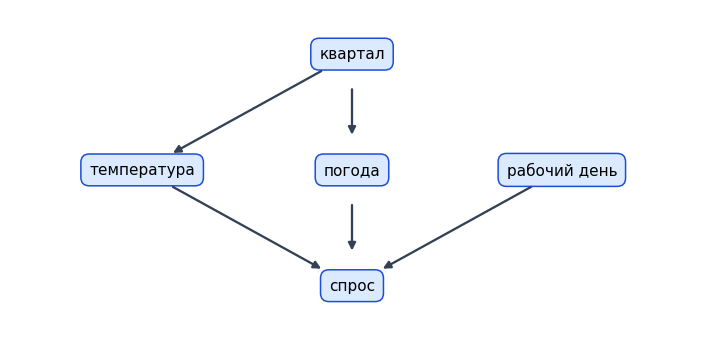

In [3]:
parents = {
    'Quarter': (),
    'Workday': (),
    'Temperature': ('Quarter',),
    'Weather': ('Quarter',),
    'Demand': ('Temperature', 'Weather', 'Workday'),
}
seen = set()
for node, upstream in parents.items():
    assert set(upstream) <= seen
    seen.add(node)
assert seen == set(states)

positions = {'Quarter': (0, 2), 'Temperature': (-1.2, 1), 'Weather': (0, 1),
             'Workday': (1.2, 1), 'Demand': (0, 0)}
labels = {'Quarter': 'квартал', 'Temperature': 'температура', 'Weather': 'погода',
          'Workday': 'рабочий день', 'Demand': 'спрос'}
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=110)
ax.set_xlim(-1.95, 1.95)
ax.set_ylim(-0.40, 2.38)
ax.axis('off')
for node, (x, y) in positions.items():
    ax.text(x, y, labels[node], ha='center', va='center', zorder=3,
            bbox=dict(boxstyle='round,pad=0.55', fc='#dbeafe', ec='#1d4ed8'))
for child, upstream in parents.items():
    for parent in upstream:
        ax.annotate('', xy=positions[child], xytext=positions[parent],
                    arrowprops=dict(arrowstyle='-|>', color='#334155', lw=1.5,
                                    shrinkA=23, shrinkB=23))
plt.show()

## 5. Оценка таблиц условных вероятностей (CPT)

Таблицы оцениваются по частотам для каждого сочетания родителей. При сглаживании Лапласа `alpha=1` вероятность состояния рассчитывается как `(count + 1) / (n + k)`, где `n` — размер группы, `k` — число состояний. Сумма вероятностей по состояниям равна единице. Для `Demand` проверяются восемь сочетаний родительских значений.

In [4]:
def fit_cpts(frame, graph, alpha=1):
    tables = {}
    for node, upstream in graph.items():
        rows = []
        for combination in product(*(states[parent] for parent in upstream)):
            condition = dict(zip(upstream, combination))
            mask = pd.Series(True, index=frame.index)
            for variable, value in condition.items():
                mask &= frame[variable].eq(value)
            counts = frame.loc[mask, node].value_counts().reindex(states[node], fill_value=0)
            n = int(counts.sum())
            probabilities = (counts + alpha) / (n + alpha * len(counts))
            assert np.isclose(probabilities.sum(), 1)
            for state, count in counts.items():
                rows.append({**condition, 'state': state, 'n': n, 'count': count,
                             'частота': count / n if n else np.nan,
                             'P сети': probabilities[state]})
        tables[node] = pd.DataFrame(rows)
    return tables

cpts = fit_cpts(data, parents)
for node, state in [('Temperature', 'warm'), ('Weather', 'reduced'), ('Demand', 'high')]:
    print(node, '=', state)
    display(cpts[node].loc[lambda t: t['state'].eq(state)].round(4))
assert cpts['Demand']['n'].min() > 0

Temperature = warm


,Quarter,state,n,count,частота,P сети
1,Q1,warm,181,13,0.0718,0.0765
3,Q2,warm,182,139,0.7637,0.7609
5,Q3,warm,184,182,0.9891,0.9839
7,Q4,warm,184,33,0.1793,0.1828


Weather = reduced


,Quarter,state,n,count,частота,P сети
1,Q1,reduced,181,71,0.3923,0.3934
3,Q2,reduced,182,62,0.3407,0.3424
5,Q3,reduced,184,57,0.3098,0.3118
7,Q4,reduced,184,78,0.4239,0.4247


Demand = high


,Temperature,Weather,Workday,state,n,count,частота,P сети
1,cool,clear,no,high,79,15,0.1899,0.1975
3,cool,clear,yes,high,137,50,0.3650,0.3669
5,cool,reduced,no,high,46,9,0.1957,0.2083
7,cool,reduced,yes,high,102,16,0.1569,0.1635
9,warm,clear,no,high,77,65,0.8442,0.8354
11,warm,clear,yes,high,170,141,0.8294,0.8256
13,warm,reduced,no,high,29,20,0.6897,0.6774
15,warm,reduced,yes,high,91,50,0.5495,0.5484


In [5]:
demand_table = cpts['Demand'].query("state == 'high'")
for day_type in states['Workday']:
    comparison = demand_table.query("Temperature == 'warm' and Workday == @day_type")
    p = comparison.set_index('Weather')['P сети']
    print(f'{day_type}: в тёплые дни, clear {p["clear"]:.1%}, reduced {p["reduced"]:.1%}')
print('наименьшая группа спроса:', demand_table['n'].min(), 'дней')

no: в тёплые дни, clear 83.5%, reduced 67.7%
yes: в тёплые дни, clear 82.6%, reduced 54.8%
наименьшая группа спроса: 29 дней


Для тёплого рабочего дня условная вероятность высокого спроса составила 82,56% при `clear` и 54,84% при `reduced`. В наименьшей группе 29 наблюдений, поэтому её оценка чувствительнее к отдельным дням.

## 6. Вероятностный вывод

Для каждой из 64 комбинаций состояний вычисляется произведение соответствующих вероятностей из CPT. При наличии наблюдений исключаются несовместимые комбинации. Оставшиеся вероятности суммируются по неизвестным узлам и нормируются по вероятности условия.

In [6]:
def joint_distribution(graph, tables):
    local = {}
    for node, upstream in graph.items():
        indexed = tables[node].set_index([*upstream, 'state'])['P сети']
        local[node] = indexed.to_dict()

    rows = []
    for values in product(*(states[node] for node in graph)):
        world = dict(zip(graph, values))
        factors = []
        for node, upstream in graph.items():
            key = tuple(world[parent] for parent in upstream) + (world[node],)
            factors.append(local[node][key if upstream else key[0]])
        rows.append({**world, 'probability': prod(factors)})
    joint = pd.DataFrame(rows)
    assert np.isclose(joint['probability'].sum(), 1)
    return joint


def query(joint, target, evidence=None):
    matching = joint
    for node, value in (evidence or {}).items():
        matching = matching.loc[matching[node].eq(value)]
    masses = matching.groupby(target)['probability'].sum().reindex(states[target], fill_value=0)
    if masses.sum() <= 0:
        raise ValueError('нет вариантов, совместимых с evidence')
    return masses / masses.sum()


joint = joint_distribution(parents, cpts)
queries = [
    ('высокий спрос | тепло', 'Demand', 'high', {'Temperature': 'warm'}),
    ('высокий спрос | погода reduced', 'Demand', 'high', {'Weather': 'reduced'}),
    ('тепло | третий квартал', 'Temperature', 'warm', {'Quarter': 'Q3'}),
]
answers = []
for label, target, state, evidence in queries:
    before = query(joint, target)[state]
    after = query(joint, target, evidence)[state]
    answers.append({'запрос': label, 'до, %': 100 * before, 'после, %': 100 * after,
                    'изменение, п.п.': 100 * (after - before)})
display(pd.DataFrame(answers).round(2))

,запрос,"до, %","после, %","изменение, п.п."
0,высокий спрос | тепло,50.46,74.81,24.35
1,высокий спрос | погода reduced,50.46,36.67,-13.78
2,тепло | третий квартал,50.20,98.39,48.18


При известном тёплом дне вероятность высокого спроса выросла с 50,46% до 74,81%, при `reduced` снизилась до 36,67%. Знание третьего квартала увеличило вероятность тёплого дня с 50,20% до 98,39%.

## 7. Последовательное добавление наблюдений

Условия добавляются в порядке `reduced`, `warm`, `Workday=yes`. Каждый следующий запрос включает ранее заданные наблюдения.

In [7]:
steps = [
    ('ничего', {}),
    ('погода reduced', {'Weather': 'reduced'}),
    ('+ тепло', {'Weather': 'reduced', 'Temperature': 'warm'}),
    ('+ рабочий день', {'Weather': 'reduced', 'Temperature': 'warm', 'Workday': 'yes'}),
]
progression = pd.DataFrame({label: query(joint, 'Demand', evidence)
                            for label, evidence in steps}).T.mul(100)
progression.columns = ['низкий спрос, %', 'высокий спрос, %']
display(progression.round(2))

,"низкий спрос, %","высокий спрос, %"
ничего,49.54,50.46
погода reduced,63.33,36.67
+ тепло,41.08,58.92
+ рабочий день,45.16,54.84


Оценка высокого спроса последовательно принимает значения 50,46%, 36,67%, 58,92% и 54,84%. Последнее значение соответствует записи CPT, поскольку заданы все родители `Demand`.

## 8. Чувствительность к структуре

Удалено ребро `Weather → Demand`, таблицы переоценены на тех же данных. Сравниваются изменения вероятности высокого спроса при `Weather=reduced` относительно исходной вероятности каждой сети.

In [8]:
fewer_parents = {**parents, 'Demand': ('Temperature', 'Workday')}
changed_joint = joint_distribution(fewer_parents, fit_cpts(data, fewer_parents))
geometry_check = []
for label, distribution in [('исходный граф', joint), ('без Weather → Demand', changed_joint)]:
    before = query(distribution, 'Demand')['high']
    after = query(distribution, 'Demand', {'Weather': 'reduced'})['high']
    geometry_check.append({'граф': label, 'без подсказки, %': 100 * before,
                           'при Weather=reduced, %': 100 * after,
                           'изменение, п.п.': 100 * (after - before)})
display(pd.DataFrame(geometry_check).round(2))

known = {'Temperature': 'warm', 'Workday': 'yes'}
without_weather = query(changed_joint, 'Demand', known)
with_weather = query(changed_joint, 'Demand', {**known, 'Weather': 'reduced'})
assert np.allclose(without_weather, with_weather)

,граф,"без подсказки, %","при Weather=reduced, %","изменение, п.п."
0,исходный граф,50.46,36.67,-13.78
1,без Weather → Demand,50.27,48.14,-2.13


Изменение составило −13,78 п. п. в исходном графе и −2,13 п. п. в сокращённом. Остаточная зависимость возникает по пути `Weather ← Quarter → Temperature → Demand`.

## 8.1. Марковское одеяло

Марковское одеяло узла состоит из его родителей, детей и остальных родителей его детей. При известных состояниях одеяла узел условно независим от остальных узлов. [Теоретический источник](https://people.csail.mit.edu/dsontag/courses/inference15/slides/lecture6_gibbs.pdf).

Одеяло спроса в исходной сети включает температуру, погоду и тип дня. После удаления `Weather → Demand` в нём остаются температура и тип дня. Численная проверка сравнивает запросы до и после добавления переменной вне одеяла.

In [9]:
def markov_blanket(graph, node):
    children = {child for child, upstream in graph.items() if node in upstream}
    other_parents = {parent for child in children for parent in graph[child] if parent != node}
    return set(graph[node]) | children | other_parents


for node in ('Demand', 'Temperature'):
    print(f'одеяло {node}:', ', '.join(sorted(markov_blanket(parents, node))))
print('одеяло Demand после удаления ребра:',
      ', '.join(sorted(markov_blanket(fewer_parents, 'Demand'))))

full_evidence = {'Temperature': 'warm', 'Weather': 'reduced', 'Workday': 'yes'}
partial_evidence = {'Weather': 'reduced', 'Workday': 'yes'}
reduced_evidence = {'Temperature': 'warm', 'Workday': 'yes'}

checks = [
    ('исходный граф: всё одеяло', joint, full_evidence, {'Quarter': 'Q3'}, 'квартал Q3'),
    ('исходный граф: без температуры', joint, partial_evidence, {'Quarter': 'Q3'}, 'квартал Q3'),
    ('сокращённый граф: всё одеяло', changed_joint, reduced_evidence, {'Weather': 'reduced'}, 'погода reduced'),
]

rows = []
for label, distribution, evidence, extra, extra_label in checks:
    before = query(distribution, 'Demand', evidence)
    after = query(distribution, 'Demand', {**evidence, **extra})
    rows.append({'случай': label, 'что добавили': extra_label,
                 'P(high) до, %': 100 * before['high'],
                 'P(high) после, %': 100 * after['high']})
    if label.endswith('всё одеяло'):
        assert np.allclose(before, after)

display(pd.DataFrame(rows).round(2))

одеяло Demand: Temperature, Weather, Workday
одеяло Temperature: Demand, Quarter, Weather, Workday
одеяло Demand после удаления ребра: Temperature, Workday


,случай,что добавили,"P(high) до, %","P(high) после, %"
0,исходный граф: всё одеяло,квартал Q3,54.84,54.84
1,исходный граф: без температуры,квартал Q3,34.03,54.22
2,сокращённый граф: всё одеяло,погода reduced,73.00,73.00


При известных состояниях исходного одеяла добавление квартала не меняет оценку (54,84%). Без наблюдаемой температуры оценка после добавления квартала меняется с 34,03% до 54,22%. В сокращённом графе при известном одеяле добавление погоды оставляет оценку 73,00%.

## 9. Выводы и ограничения

Оценки подтверждают связь температуры и погодной категории со спросом в пределах предложенной сети. Удаление прямого ребра ослабляет влияние сведений о погоде; косвенный путь сохраняется.

Сеть описывает условные зависимости в наблюдательных данных. Направления рёбер и предположения о независимости заданы исследователем. Причинные эффекты не оценивались. Обобщение ограничено одним велопрокатом, 2011–2012 гг., грубой дискретизацией и отсутствием ряда факторов, включая рост сервиса и городские события.